30 + 58*exp(-0.075*t)

-4.35*exp(-0.075*t)

-2.989708362740729

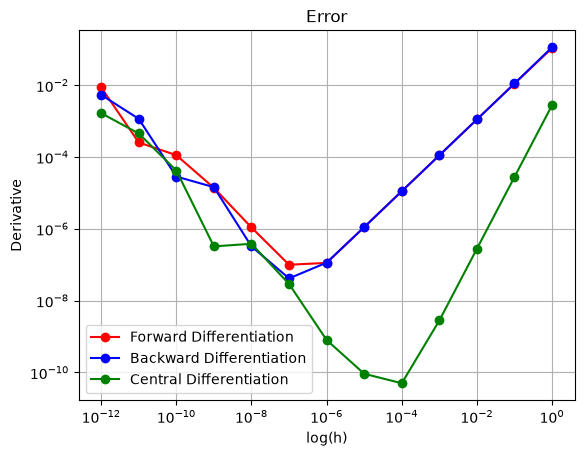

In [26]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display

t = sp.symbols('t')
T = 30 + 58*(sp.exp(-0.075*t))
display(T)

Rate_Cooling = sp.diff(T,t)
display(Rate_Cooling)
display(float(Rate_Cooling.subs(t,5)))

def T(x):
    Temp = 30 + 58*(np.exp(-0.075*x))
    return Temp

def forward(f,x,h):
    diff = (f(x+h) - f(x))/h
    return diff

def backward(f,x,h):
    diff = (f(x) - f(x-h))/h
    return diff

def central(f,x,h):
    diff = (f(x+h) - f(x-h))/(2*h)
    return diff

h_list = []

for i in range(0,-13,-1):
    h_list.append(10**i)

h_arr = np.array(h_list)

true_val = -58*0.075*np.exp(-0.075*5)
err_f = np.abs(forward(T,5,h_arr) - true_val)
err_b = np.abs(backward(T,5,h_arr) - true_val)
err_c = np.abs(central(T,5,h_arr) - true_val)


plt.loglog(h_arr,err_f, "r-", label = "Forward Differentiation", marker = "o")
plt.loglog(h_arr,err_b, "b-", label = "Backward Differentiation", marker = "o")
plt.loglog(h_arr,err_c, "g-", label = "Central Differentiation", marker = "o")
plt.xlabel("log(h)")
plt.ylabel("Derivative")
plt.title("Error")
plt.legend()
plt.grid()
plt.show()



######## From the graph we can conclude that forward and backward differentiation formmula would result in error proportional to h
########## And the central differentiation formula would result in error proportional to (h**2)


### For very small h, f(x+h) and f(x) are nearly equal, so subtracting them causes catastrophic cancellation: 
### most significant digits are lost and only rounding noise (of size about machine epsilon, ≈2.2×10⁻¹⁶, times f) remains. Dividing this 
### noise by the tiny h amplifies it, so the round-off error grows like ε/h. Total error = truncation error (decreasing with h) + round-off 
### error (increasing as h decreases), so the log-log curve is V-shaped,with a minimum at an optimal h and a rise after that.

[ 0.9   1.8   3.6   5.4   7.2   9.   10.4  10.8  10.75 10.8  10.2   8.3
  5.75  3.3   2.1 ]
[0.0, 1.8, 1.7999999999999998, 1.8000000000000007, 1.8000000000000007, 1.7999999999999972, 1.0, -0.19999999999998863, 0.09999999999999432, 0.0, -1.1999999999999886, -2.5999999999999943, -2.5, -2.4000000000000057, 0.0]


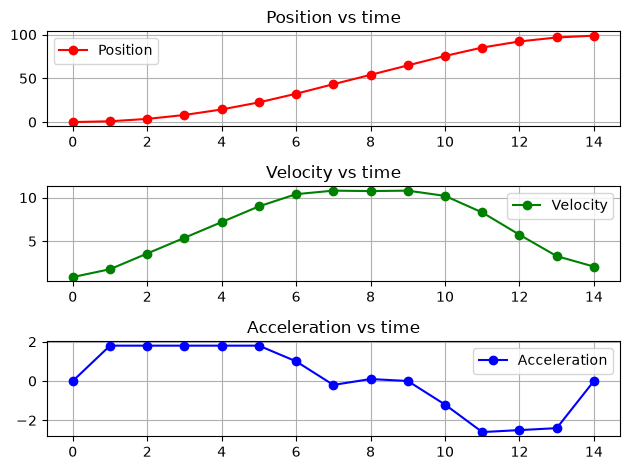

[ 0.9   1.8   3.6   5.4   7.2   9.   10.4  10.8  10.75 10.8  10.2   8.3
  5.75  3.3   2.1 ]
1.4285714285714284
1.583333333333333
-2.1750000000000007


In [4]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

t = np.array([0,1,2,3,4,5,6,7,8,9,10,11,12,13,14])
s = np.array([0.0,0.9,3.6,8.1,14.4,22.5,32.4,43.3,54.0,64.8,75.6,85.2,92.2,96.7,98.8])

velocity=[]

def forward(f,x,h):
    differentiation = (f(x+h) - f(x))/h
    return differentiation

def backward(f,x,h):
    differentiation = (f(x) - f(x-h))/h
    return differentiation

def central(f,x,h):
    differentiation = (f(x+h) - f(x-h))/(2*h)
    return differentiation

def f(x):
    element = float(s[x])
    return element

for i in range(0,15,1):
    if (i==0):
        velocity.append(forward(f,i,1))
    elif(i==14):
        velocity.append(backward(f,i,1))
    else:
        velocity.append(central(f,i,1))

print(np.round(velocity,2))

def second_derivative(f,x,h):
    second_derivative = (f(x+h) + f(x-h) - (2*f(x)))/(h**2)
    return second_derivative
 
acc = [0.0]
for i in range(1,14,1):
    acc.append(second_derivative(f,i,1))
acc.append(0.0)
print(acc)

#for i in range(0,15,1):
#    velocity[i] = velocity[i] * (5/18)
#print(velocity)                                          Getting in km/h

fig,ax = plt.subplots(3,1)
ax[0].plot(t,s, "ro-", label = "Position")
ax[0].set_title("Position vs time")
ax[0].legend()
ax[0].grid(True)
ax[1].plot(t,velocity, "go-", label = "Velocity")
ax[1].set_title("Velocity vs time")
ax[1].legend()
ax[1].grid(True)
ax[2].plot(t,acc, "bo-", label = "Acceleration")
ax[2].set_title("Acceleration vs time")
ax[2].legend()
ax[2].grid(True)

plt.tight_layout()
plt.show()

velocity_new = np.gradient(s,t)
print(velocity_new)


########The acceleration while speeding up:

i = 0
sum = 0
while(acc[i]>=0):
    sum = sum + acc[i]
    i = i+1
print(float(sum/i))

i=1
sum = 0
while(acc[i]>=0):
    sum = velocity[i] - velocity[0]
    i = i+1
print(float(sum/(i-1)))

# Cruising speed = 10.5 * 3.6 = 37.8 km/h

#########Breaking Deceleration

i = 10
j = 0
while(acc[i]<=0):
    sum = velocity[i] - velocity[9]
    j = j+1
    i = i+1
    if(i==15):
        break
print(float(sum/(j-1)))

[0.0, 0.0, 0.019, 0.15, 0.46699999999999997, 0.9400000000000001, 1.5, 2.0599999999999996, 2.5330000000000004, 2.85, 2.9619999999999997, 2.8499999999999996, 2.5329999999999995, 2.0600000000000005, 1.5, 0.9399999999999995, 0.4670000000000005, 0.15000000000000036, 0.019000000000000128, 0.0, 0.0]
[0.0, 0.0, 0.076, 0.44799999999999995, 0.8200000000000001, 1.072, 1.1679999999999993, 1.072000000000001, 0.8200000000000003, 0.4480000000000004, 0.0, -0.4480000000000004, -0.8200000000000074, -1.0720000000000027, -1.1680000000000064, -1.0720000000000027, -0.8200000000000074, -0.4479999999999933, -0.0759999999999934, 0.0, 0.0]
2.9619999999999997
10
1.1679999999999993
6


H*(-sin(2*pi*t0/T)/(2*pi) + t0/T)

3*t/2 - 6*sin(pi*(t/4 - 1/4))/pi - 3/2

3/2 - 3*cos(pi*(t/4 - 1/4))/2

3*pi*sin(pi*(t/4 - 1/4))/8

[0.0, 0.15, 0.79, 1.1199999999999997, 0.79, 0.0, -0.7899999999999991, -1.120000000000001, -0.7899999999999991, -0.14999999999999858, 0.0]
1.1199999999999997


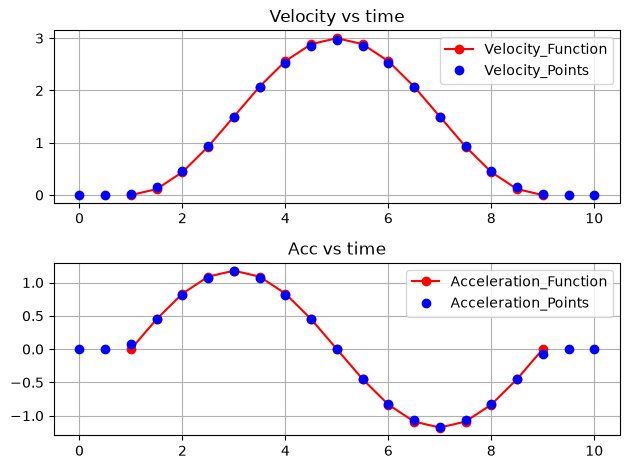

In [35]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display


z_list = [0.000,0.000,0.000,0.019,0.150,0.486,1.090,1.986,3.150,4.519,6.000,7.481,8.850,10.014,10.910,11.514,11.850,11.981,12.000,12.000,12.000]
t_list = [0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0,6.5,7.0,7.5,8.0,8.5,9.0,9.5,10.0]

def forward(f,x,h):
    differentiation = (f(x+1) - f(x))/h
    return differentiation

def backward(f,x,h):
    differentiation = (f(x) - f(x-1))/h
    return differentiation

def central(f,x,h):
    differentiation = (f(x+1) - f(x-1))/(2*h)
    return differentiation

def f(x):
    element = float(z_list[x])
    return element

def second_derivative(f,x,h):
    second_derivative = (f(x+1) + f(x-1) - (2*f(x)))/(h**2)
    return second_derivative
    
velocity=[]
for i in range(0,21,1):
    if(i==0):
        velocity.append(forward(f,i,0.5))
    elif(i==20):
        velocity.append(backward(f,i,0.5))
    else:
        velocity.append(central(f,i,0.5))

print(velocity)

acc = [0.0]
for i in range(1,20,1):
    acc.append(second_derivative(f,i,0.5))
acc.append(0.0)
print(acc)

max_velocity = max(velocity)
print(max_velocity)
count_vel = 0
for i in velocity:
    if(i == max_velocity):
        break
    else:
        pass
    count_vel = count_vel + 1
print(count_vel)

max_acc = max(acc)
print(max_acc)
count_acc = 0
for j in acc:
    if(j == max_acc):
        break
    else:
        pass
    count_acc = count_acc + 1
print(count_acc)

t = sp.symbols('t')
T = sp.symbols('T')
H = sp.symbols('H')
t0 = sp.symbols('t0')
z = H*((t0/T) - ((1/(2*(sp.pi)))*sp.sin(2*(sp.pi)*(t0/T))))
display(z)
z = z.subs(t0, t-1)
z = z.subs(T,8)
z = z.subs(H,12)
display(z)

v = sp.diff(z,t)
display(v)

a = sp.diff(v,t)
display(a)

def g(x):
    element = float(z_new[x])
    return element

time_new = [0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0]
z_new = [0.000,0.000,0.150,1.090,3.150,6.000,8.850,10.910,11.850,12.000,12.000]

acc_new = [0.0]
for i in range(1,10,1):
    acc_new.append(second_derivative(g,i,1))
acc_new.append(0.0)
print(acc_new)
max_acc_new = max(acc_new)
print(max_acc_new)

time = [1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0,6.5,7.0,7.5,8.0,8.5,9.0]
expr_velocity = sp.lambdify(t,v,'numpy')
vel_arr = expr_velocity(np.array(time))
expr_acc = sp.lambdify(t,a,'numpy')
acc_arr = expr_acc(np.array(time))

fig,ax = plt.subplots(2,1)
ax[0].plot(time,vel_arr,'ro-', label = 'Velocity_Function')
ax[0].plot(t_list,velocity, 'bo', label = 'Velocity_Points')
ax[0].set_title('Velocity vs time')
ax[0].legend()
ax[0].grid(True)
ax[1].plot(time,acc_arr,'ro-', label = 'Acceleration_Function')
ax[1].plot(t_list,acc, 'bo', label = 'Acceleration_Points')
ax[1].set_title('Acc vs time')
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

## Lift is comfortable
for i in range(0,21,1):
    if(acc[i]>1.5):
        print("Notcomfortable")
        break
    else:
        pass

In [36]:
import sympy as sp

x = sp.symbols('x')
display(x)

x